# comprension_eda.ipynb – Comprensión del negocio y análisis exploratorio

## 1. Comprensión del negocio

**Contexto.** Una entidad otorga créditos de consumo a personas empleadas e independientes. Cada crédito
queda registrado con las condiciones del préstamo, el perfil del cliente y la información del reporte de
centrales de riesgo (tipo DataCrédito) al momento del desembolso.

**Problema.** Predecir si un cliente **pagará a tiempo** (`Pago_atiempo = 1`) o **no** (`Pago_atiempo = 0`).

**Valor para el negocio.** Un modelo que anticipe el incumplimiento permite aprobar con mejor criterio, ajustar
montos/plazos o pedir garantías, reduciendo pérdidas por cartera vencida.

**Tipo de problema.** Clasificación supervisada binaria con **clases desbalanceadas** (la clase de interés, `0`, es la minoritaria).

**Qué se hace en este notebook** (según el PDF guía):
1. Exploración inicial: caracterización de variables, nulos, tipos de datos.
2. EDA univariable, bivariable y multivariable.
3. Reglas de validación de datos, transformaciones sugeridas y variables derivadas.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

import ft_engineering as fe   # funciones de limpieza compartidas con el pipeline

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

TARGET = "Pago_atiempo"
PALETA = ["#d62728", "#2ca02c"]   # rojo = no paga (0), verde = paga (1)
df_raw = fe.cargar_datos()          # copia cruda: nunca se modifica
df = df_raw.copy()
print(f"Dimensiones: {df.shape}")

Dimensiones: (10763, 23)


## 2. Exploración inicial de los datos

### 2.1 Descripción general

In [2]:
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.000",12,32,Empleado,3500000,1000000,128650,95.228,795.000,0,2,0.000,0.000,NaN,NaN,0,0,0,"916,148.000",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.000",6,34,Empleado,5000000,2000000,441817,95.228,796.000,0,7,0.000,0.000,NaN,NaN,0,0,0,"4,473,774.000",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.000",5,34,Independiente,5000000,2000000,108632,95.228,727.000,5,0,0.000,"274,561.000","274,561.000",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.800",2,25,Independiente,3000000,900000,199684,95.228,864.000,8,1,0.000,"27,564.000","27,564.000",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.000",10,26,Empleado,2000000,600000,92509,95.228,771.000,0,3,0.000,0.000,NaN,NaN,0,0,0,"61,000.000",Creciente,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

### 2.2 Caracterización de las variables

Clasificación estadística de cada columna (categórica / numérica, y dentro de cada una su subtipo):

In [4]:
caracterizacion = pd.DataFrame([
    ("tipo_credito",                  "Categórica", "Nominal politómica",  "Código del producto de crédito (4, 9, 10, 6, 7, 68)"),
    ("fecha_prestamo",                "Fecha",      "Temporal",            "Fecha y hora del desembolso"),
    ("capital_prestado",              "Numérica",   "Continua",            "Valor prestado ($)"),
    ("plazo_meses",                   "Numérica",   "Discreta",            "Plazo del crédito en meses"),
    ("edad_cliente",                  "Numérica",   "Discreta",            "Edad en años"),
    ("tipo_laboral",                  "Categórica", "Nominal dicotómica",  "Empleado / Independiente"),
    ("salario_cliente",               "Numérica",   "Continua",            "Ingreso mensual declarado ($)"),
    ("total_otros_prestamos",         "Numérica",   "Continua",            "Monto de otros préstamos del cliente ($)"),
    ("cuota_pactada",                 "Numérica",   "Continua",            "Cuota mensual del crédito ($)"),
    ("puntaje",                       "Numérica",   "Continua",            "Puntaje interno (¡sospechoso de fuga de datos!)"),
    ("puntaje_datacredito",           "Numérica",   "Continua",            "Score de la central de riesgo (150–950)"),
    ("cant_creditosvigentes",         "Numérica",   "Discreta (conteo)",   "Número de créditos vigentes"),
    ("huella_consulta",               "Numérica",   "Discreta (conteo)",   "Consultas recientes al historial del cliente"),
    ("saldo_mora",                    "Numérica",   "Continua",            "Saldo en mora ($)"),
    ("saldo_total",                   "Numérica",   "Continua",            "Saldo total de deuda ($)"),
    ("saldo_principal",               "Numérica",   "Continua",            "Saldo de capital ($)"),
    ("saldo_mora_codeudor",           "Numérica",   "Continua",            "Saldo en mora del codeudor ($)"),
    ("creditos_sectorFinanciero",     "Numérica",   "Discreta (conteo)",   "Créditos en el sector financiero"),
    ("creditos_sectorCooperativo",    "Numérica",   "Discreta (conteo)",   "Créditos en el sector cooperativo"),
    ("creditos_sectorReal",           "Numérica",   "Discreta (conteo)",   "Créditos en el sector real"),
    ("promedio_ingresos_datacredito", "Numérica",   "Continua",            "Ingreso promedio reportado por la central ($)"),
    ("tendencia_ingresos",            "Categórica", "Ordinal",             "Decreciente < Estable < Creciente"),
    ("Pago_atiempo",                  "Objetivo",   "Dicotómica (0/1)",    "1 = pagó a tiempo, 0 = no pagó a tiempo"),
], columns=["variable", "clase", "subtipo", "descripción"])
caracterizacion

,variable,clase,subtipo,descripción
0,tipo_credito,Categórica,Nominal politómica,"Código del producto de crédito (4, 9, 10, 6, 7..."
1,fecha_prestamo,Fecha,Temporal,Fecha y hora del desembolso
2,capital_prestado,Numérica,Continua,Valor prestado ($)
3,plazo_meses,Numérica,Discreta,Plazo del crédito en meses
4,edad_cliente,Numérica,Discreta,Edad en años
5,tipo_laboral,Categórica,Nominal dicotómica,Empleado / Independiente
6,salario_cliente,Numérica,Continua,Ingreso mensual declarado ($)
7,total_otros_prestamos,Numérica,Continua,Monto de otros préstamos del cliente ($)
8,cuota_pactada,Numérica,Continua,Cuota mensual del crédito ($)
9,puntaje,Numérica,Continua,Puntaje interno (¡sospechoso de fuga de datos!)


**Interpretación.** Hay 18 variables numéricas (continuas y de conteo; una de ellas, `puntaje`, es sospechosa), 3 categóricas (2 nominales y 1 ordinal), 1 fecha y 1 objetivo dicotómico.
La variable `tipo_credito` viene como número pero **es un código de categoría** (no tiene sentido sumar o promediar códigos), así que se tratará como categórica nominal.


### 2.3 Revisión de nulos

In [5]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
})
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
nulos

,nulos,porcentaje
tendencia_ingresos,2932,27.240
promedio_ingresos_datacredito,2930,27.220
saldo_mora_codeudor,590,5.480
saldo_principal,405,3.760
saldo_mora,156,1.450
saldo_total,156,1.450
puntaje_datacredito,6,0.060


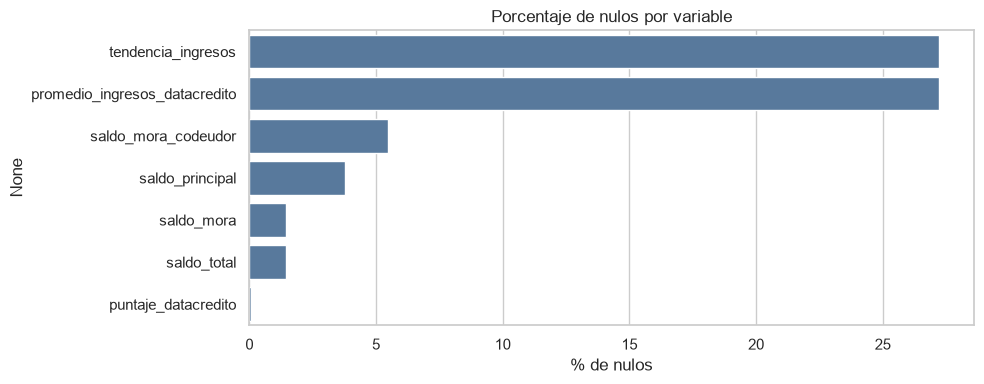

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=nulos["porcentaje"], y=nulos.index, color="#4c78a8", ax=ax)
ax.set_title("Porcentaje de nulos por variable")
ax.set_xlabel("% de nulos")
plt.tight_layout(); plt.show()

**Interpretación de los nulos.**

* `promedio_ingresos_datacredito` (~27 %) y `tendencia_ingresos` (~27 %) faltan **casi siempre juntas**: son clientes sin historial de ingresos en la central. No es un error aleatorio, es información (*missing not at random*).
* `saldo_mora`, `saldo_total` (1,4 %) y `saldo_mora_codeudor` (5,5 %) son nulos puntuales del reporte.
* `saldo_principal` tiene 405 nulos: **249 corresponden a clientes con `saldo_total = 0`** (no tienen deuda, así que el saldo principal es 0 y no un dato perdido). Lo verificamos:

In [7]:
pd.crosstab(df["saldo_total"].isna(), df["saldo_principal"].isna(),
            rownames=["saldo_total nulo"], colnames=["saldo_principal nulo"])

saldo_principal nulo,False,True
saldo_total nulo,,
False,10358,249
True,0,156


In [8]:
sin_deuda = (df["saldo_total"] == 0) & df["saldo_principal"].isna()
print(f"Registros con saldo_total = 0 y saldo_principal nulo: {sin_deuda.sum()}  -> se reemplazan por 0")
print()
print("Nulos de promedio_ingresos_datacredito vs tendencia_ingresos:")
pd.crosstab(df["promedio_ingresos_datacredito"].isna(), df["tendencia_ingresos"].isna(),
            rownames=["promedio_ingresos nulo"], colnames=["tendencia nulo"])

Registros con saldo_total = 0 y saldo_principal nulo: 249  -> se reemplazan por 0

Nulos de promedio_ingresos_datacredito vs tendencia_ingresos:


tendencia nulo,False,True
promedio_ingresos nulo,,
False,7831,2
True,0,2930


### 2.4 Unificar la representación de los valores nulos

Los nulos deben representarse de una sola forma (`NaN`). Hay que revisar si existen "nulos disfrazados"
(textos como `"NA"`, `"?"`, vacío, etc.) y valores que no pertenecen al dominio de la variable.

In [9]:
print("Valores únicos de tendencia_ingresos (con conteo):")
df["tendencia_ingresos"].value_counts(dropna=False).head(15)

Valores únicos de tendencia_ingresos (con conteo):


tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
Name: count, dtype: int64

**Hallazgo.** `tendencia_ingresos` debería tener solo 3 categorías (*Creciente, Estable, Decreciente*), pero aparecen
**valores numéricos** (`0`, `8315`, `1000000`, `-28589`, ...). Son errores de captura (probablemente un desplazamiento de columnas). Se convierten a `NaN`.
Además se buscan textos que signifiquen "nulo" en las demás columnas de texto:

In [10]:
print("Tokens de nulo que se unifican:", fe.VALORES_NULOS)
columnas_texto = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in columnas_texto:
    if col == "fecha_prestamo":
        continue
    disfrazados = df[col].isin(fe.VALORES_NULOS).sum()
    print(f"{col:22s} nulos disfrazados: {disfrazados}")

# Registros de tendencia_ingresos fuera del dominio
validos = df["tendencia_ingresos"].astype("string").str.strip().str.capitalize()
fuera = validos.notna() & ~validos.isin(fe.ORDEN_TENDENCIA)
print(f"\nRegistros de tendencia_ingresos con valor inválido: {fuera.sum()}  -> se convierten a NaN")

Tokens de nulo que se unifican: ['', ' ', 'NA', 'N/A', 'NaN', 'nan', 'NULL', 'null', 'None', 'none', '?', '-']
tipo_laboral           nulos disfrazados: 0
tendencia_ingresos     nulos disfrazados: 0

Registros de tendencia_ingresos con valor inválido: 58  -> se convierten a NaN


### 2.5 Eliminación de variables irrelevantes

Se revisa si hay columnas constantes, duplicadas, identificadores o con **fuga de información** (*data leakage*).

In [11]:
print("Filas duplicadas:", df.duplicated().sum())
print("Columnas constantes:", [c for c in df.columns if df[c].nunique(dropna=False) <= 1])
print("Columnas con ID (valores únicos = filas):", [c for c in df.columns if df[c].nunique() == len(df)])

Filas duplicadas: 0
Columnas constantes: []
Columnas con ID (valores únicos = filas): []


No hay duplicados, ni columnas constantes ni identificadores. Pero una variable llama la atención: **`puntaje`**.
Su correlación con el objetivo es altísima. Se investiga:

In [12]:
print("Correlación puntaje vs Pago_atiempo:", round(df["puntaje"].corr(df[TARGET]), 3))
print("AUC usando SOLO la variable 'puntaje':", round(roc_auc_score(df[TARGET], df["puntaje"]), 4))
print()
print(df.groupby(TARGET)["puntaje"].describe().round(2))
print()
es_tope = df["puntaje"].round(4) == 95.2278
print("¿puntaje = 95.2278 (valor máximo)?  vs  Pago_atiempo")
pd.crosstab(es_tope, df[TARGET], rownames=["puntaje == 95.2278"], colnames=["Pago_atiempo"])

Correlación puntaje vs Pago_atiempo: 0.923
AUC usando SOLO la variable 'puntaje': 1.0

                  count   mean    std     min    25%    50%    75%    max
Pago_atiempo                                                             
0               511.000 23.090 26.070 -38.010 -3.590 25.420 47.610 62.670
1            10,252.000 94.560  2.870  63.810 95.230 95.230 95.230 95.230

¿puntaje = 95.2278 (valor máximo)?  vs  Pago_atiempo


Pago_atiempo,0,1
puntaje == 95.2278,,
False,511,845
True,0,9407


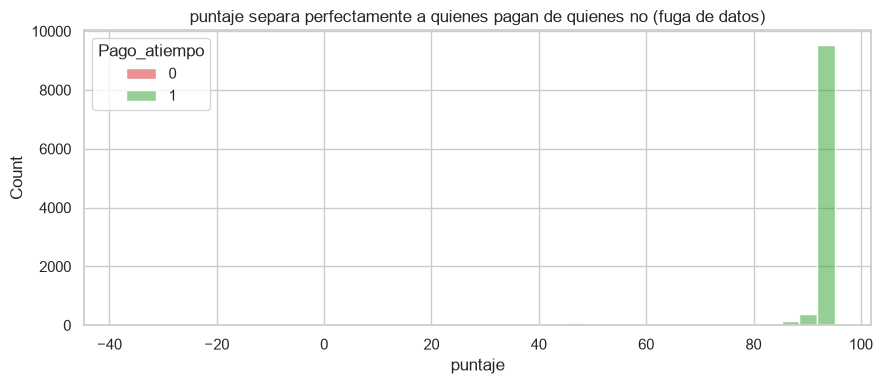

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="puntaje", hue=TARGET, bins=40, palette=PALETA, ax=ax)
ax.set_title("puntaje separa perfectamente a quienes pagan de quienes no (fuga de datos)")
plt.tight_layout(); plt.show()

**Conclusión importante – fuga de datos (*data leakage*).**
`puntaje` por sí sola logra un **AUC de 1.0**: *todos* los clientes que no pagaron tienen un puntaje menor a 63 y *ninguno* de los que tienen el valor tope (95,23) incumplió.
Es casi seguro que este puntaje se calculó **después** de conocer el comportamiento de pago (por ejemplo, un score de comportamiento interno). En producción, al momento de aprobar un crédito, **esa información no existe**.
Si se incluyera, el modelo parecería perfecto en el laboratorio y fallaría en la vida real.

👉 **Decisión: se excluye `puntaje` del modelo.** (Queda registrada en `ft_engineering.COLUMNAS_EXCLUIDAS`.)

`fecha_prestamo` tampoco entra como predictor (evita que el modelo memorice épocas), pero **se conserva** porque permite ordenar en el tiempo y hacer el monitoreo de data drift.


### 2.6 Conversión de tipos y corrección de datos

Se revisan los rangos de las variables numéricas para encontrar valores imposibles o centinelas:

In [14]:
df_raw[["edad_cliente", "salario_cliente", "total_otros_prestamos", "puntaje_datacredito",
        "capital_prestado", "plazo_meses", "cuota_pactada"]].describe().T

,count,mean,std,min,25%,50%,75%,max
edad_cliente,"10,763.000",43.949,15.061,19.000,33.000,42.000,53.000,123.000
salario_cliente,"10,763.000","17,216,431.460","355,476,717.603",0.000,"2,000,000.000","3,000,000.000","4,875,808.000","22,000,000,000.000"
total_otros_prestamos,"10,763.000","6,238,869.649","118,418,316.941",0.000,"500,000.000","1,000,000.000","2,000,000.000","6,787,675,263.000"
puntaje_datacredito,"10,757.000",780.791,104.878,-7.000,757.000,791.000,825.000,999.000
capital_prestado,"10,763.000","2,434,315.001","1,909,642.759","360,000.000","1,224,831.000","1,921,920.000","3,084,840.000","41,444,152.800"
plazo_meses,"10,763.000",10.576,6.632,2.000,6.000,10.000,12.000,90.000
cuota_pactada,"10,763.000","243,617.407","210,493.695","23,944.000","121,041.500","182,863.000","287,833.500","3,816,752.000"


In [15]:
print("Edades más frecuentes:", df_raw["edad_cliente"].value_counts().head(4).to_dict())
print("Clientes con edad > 100:", (df_raw["edad_cliente"] > 100).sum(), " (¿todos con 122?)", (df_raw["edad_cliente"] == 122).sum())
print("Salarios = 0:", (df_raw["salario_cliente"] == 0).sum(), "| salarios > 100 millones:", (df_raw["salario_cliente"] > 1e8).sum())
print("Salario máximo:", f"{df_raw['salario_cliente'].max():,.0f}")
print("puntaje_datacredito fuera de [150, 950]:", ((df_raw["puntaje_datacredito"] < 150) | (df_raw["puntaje_datacredito"] > 950)).sum())
print("Valores de puntaje_datacredito fuera de rango:", sorted(df_raw.loc[(df_raw["puntaje_datacredito"] < 150) | (df_raw["puntaje_datacredito"] > 950), "puntaje_datacredito"].unique())[:10])

Edades más frecuentes: {40: 346, 37: 344, 38: 339, 42: 333}
Clientes con edad > 100: 150  (¿todos con 122?) 144
Salarios = 0: 24 | salarios > 100 millones: 74
Salario máximo: 22,000,000,000
puntaje_datacredito fuera de [150, 950]: 153
Valores de puntaje_datacredito fuera de rango: [np.float64(-7.0), np.float64(0.0), np.float64(7.0), np.float64(951.0), np.float64(968.0), np.float64(969.0), np.float64(978.0), np.float64(987.0), np.float64(999.0)]


**Hallazgos de calidad.**

* `edad_cliente = 122` aparece **144 veces**: es un valor centinela ("sin dato"), no una edad real. Edades > 100 → nulo.
* `salario_cliente` tiene ceros y valores absurdos (hasta **22 mil millones** al mes). Se consideran inválidos los salarios ≤ 0 o > 100 millones.
* `total_otros_prestamos` tiene 13 valores > 1.000 millones, casi seguro errores de digitación.
* `puntaje_datacredito` tiene valores fuera del rango real del score (150–950), como `999` o negativos.

**Reglas aplicadas (`ft_engineering.limpiar_datos`):** los valores fuera de rango se convierten a `NaN`, para luego imputarlos con la mediana dentro del pipeline (sin tocar la base original).


In [16]:
fe.validar_datos(df_raw)

,variable,minimo_valido,maximo_valido,registros_invalidos,porcentaje
0,edad_cliente,18.000,100.000,150,1.394
1,salario_cliente,1.000,"100,000,000.000",98,0.911
2,total_otros_prestamos,0.000,"1,000,000,000.000",13,0.121
3,puntaje_datacredito,150.000,950.000,153,1.422
4,capital_prestado,1.000,NaN,0,0.000
5,plazo_meses,1.000,120.000,0,0.000
6,cuota_pactada,1.000,NaN,0,0.000
7,tendencia_ingresos,NaN,NaN,58,0.539


In [17]:
# Aplicamos la limpieza oficial del pipeline y verificamos los tipos resultantes
df = fe.limpiar_datos(df_raw)
print(df.dtypes.to_string())
print()
print("Nulos después de limpiar (solo columnas con nulos):")
resultado = df.isna().sum()
resultado[resultado > 0].sort_values(ascending=False).to_frame("nulos")

tipo_credito                             object
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                             float64
edad_cliente                            float64
tipo_laboral                             object
salario_cliente                         float64
total_otros_prestamos                   float64
cuota_pactada                           float64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
saldo_mora_codeudor                     float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           

,nulos
tendencia_ingresos,2990
promedio_ingresos_datacredito,2930
saldo_mora_codeudor,590
puntaje_datacredito,159
saldo_mora,156
saldo_total,156
saldo_principal,156
edad_cliente,150
salario_cliente,98
total_otros_prestamos,13


Ahora cada columna tiene un tipo uniforme: numéricas como `float/int`, `tipo_credito`, `tipo_laboral` y `tendencia_ingresos` como categóricas (texto) y `fecha_prestamo` como `datetime`.

## 3. Exploración de datos y descripción (EDA)

### 3.1 Análisis univariable – variables numéricas

In [18]:
numericas = fe.VARIABLES_NUMERICAS_BASE
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.000","2,434,315.001","1,909,642.759","360,000.000","1,224,831.000","1,921,920.000","3,084,840.000","41,444,152.800"
plazo_meses,"10,763.000",10.576,6.632,2.000,6.000,10.000,12.000,90.000
edad_cliente,"10,613.000",42.846,11.947,19.000,33.000,42.000,52.000,69.000
salario_cliente,"10,665.000","4,115,410.950","5,102,723.148","1,000.000","2,000,000.000","3,000,000.000","4,760,000.000","95,985,077.000"
total_otros_prestamos,"10,750.000","2,783,929.400","24,826,126.953",0.000,"500,000.000","1,000,000.000","2,000,000.000","934,303,642.000"
cuota_pactada,"10,763.000","243,617.407","210,493.695","23,944.000","121,041.500","182,863.000","287,833.500","3,816,752.000"
puntaje_datacredito,"10,604.000",791.505,50.693,287.000,758.000,792.000,826.000,947.000
cant_creditosvigentes,"10,763.000",5.727,3.977,0.000,3.000,5.000,8.000,62.000
huella_consulta,"10,763.000",4.229,3.065,0.000,2.000,4.000,6.000,29.000
saldo_mora,"10,607.000",7.746,225.955,0.000,0.000,0.000,0.000,"12,534.000"


In [19]:
def tipo_distribucion(serie):
    s = serie.dropna()
    if s.nunique() <= 2:
        return "dicotómica"
    asim, curt = stats.skew(s), stats.kurtosis(s)
    if abs(asim) < 0.5 and curt < -0.8:
        return "casi uniforme (platicúrtica)"
    if abs(asim) < 0.5:
        return "aprox. gaussiana"
    if asim >= 1:
        return "asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
    if asim <= -1:
        return "asimétrica negativa (cola izquierda)"
    return "moderadamente asimétrica"

filas = []
for col in numericas:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    filas.append({
        "variable": col, "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "min": s.min(), "max": s.max(), "rango": s.max() - s.min(), "Q1": q1, "Q3": q3,
        "IQR": q3 - q1, "varianza": s.var(), "desv_est": s.std(),
        "skewness": stats.skew(s), "kurtosis": stats.kurtosis(s), "distribución": tipo_distribucion(s),
    })
resumen_num = pd.DataFrame(filas).set_index("variable")
resumen_num.style.format({c: "{:,.2f}" for c in resumen_num.columns if c != "distribución"})

,media,mediana,moda,min,max,rango,Q1,Q3,IQR,varianza,desv_est,skewness,kurtosis,distribución
variable,,,,,,,,,,,,,,
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80","1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",3.72,35.30,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
plazo_meses,10.58,10.00,6.00,2.00,90.00,88.00,6.00,12.00,6.00,43.98,6.63,2.46,7.78,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
edad_cliente,42.85,42.00,40.00,19.00,69.00,50.00,33.00,52.00,19.00,142.74,11.95,0.27,-0.86,casi uniforme (platicúrtica)
salario_cliente,"4,115,410.95","3,000,000.00","3,000,000.00","1,000.00","95,985,077.00","95,984,077.00","2,000,000.00","4,760,000.00","2,760,000.00","26,037,783,522,052.30","5,102,723.15",8.68,113.11,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
total_otros_prestamos,"2,783,929.40","1,000,000.00","2,000,000.00",0.00,"934,303,642.00","934,303,642.00","500,000.00","2,000,000.00","1,500,000.00","616,336,579,475,531.12","24,826,126.95",26.11,767.69,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00","121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",3.79,26.64,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
puntaje_datacredito,791.50,792.00,783.00,287.00,947.00,660.00,758.00,826.00,68.00,"2,569.80",50.69,-0.71,5.24,moderadamente asimétrica
cant_creditosvigentes,5.73,5.00,4.00,0.00,62.00,62.00,3.00,8.00,5.00,15.82,3.98,1.80,8.62,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"
huella_consulta,4.23,4.00,2.00,0.00,29.00,29.00,2.00,6.00,4.00,9.39,3.06,1.49,4.00,"asimétrica positiva (cola derecha, tipo log-normal/exponencial)"


**Interpretación.**

* Casi todas las variables monetarias (`capital_prestado`, `salario_cliente`, `cuota_pactada`, saldos, ingresos) son **muy asimétricas a la derecha** (skewness > 2) y con colas pesadas (kurtosis muy alta): pocos clientes con montos enormes. Su media es mucho mayor que la mediana, por eso **la mediana es mejor medida de tendencia central** y conviene imputar con ella.
* `edad_cliente` es la más "simétrica" (skewness ≈ 0,3) y algo aplanada (kurtosis negativa): se parece a una distribución casi uniforme entre 20 y 70 años.
* `puntaje_datacredito` es asimétrica negativa (cola hacia puntajes bajos) con la mayoría de clientes entre 750 y 850.
* Las variables de conteo (`cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`) siguen distribuciones tipo Poisson (asimetría positiva).
* `saldo_mora` y `saldo_mora_codeudor` son **casi siempre 0** (la mediana es 0): son variables muy dispersas, informativas solo para los pocos clientes en mora.


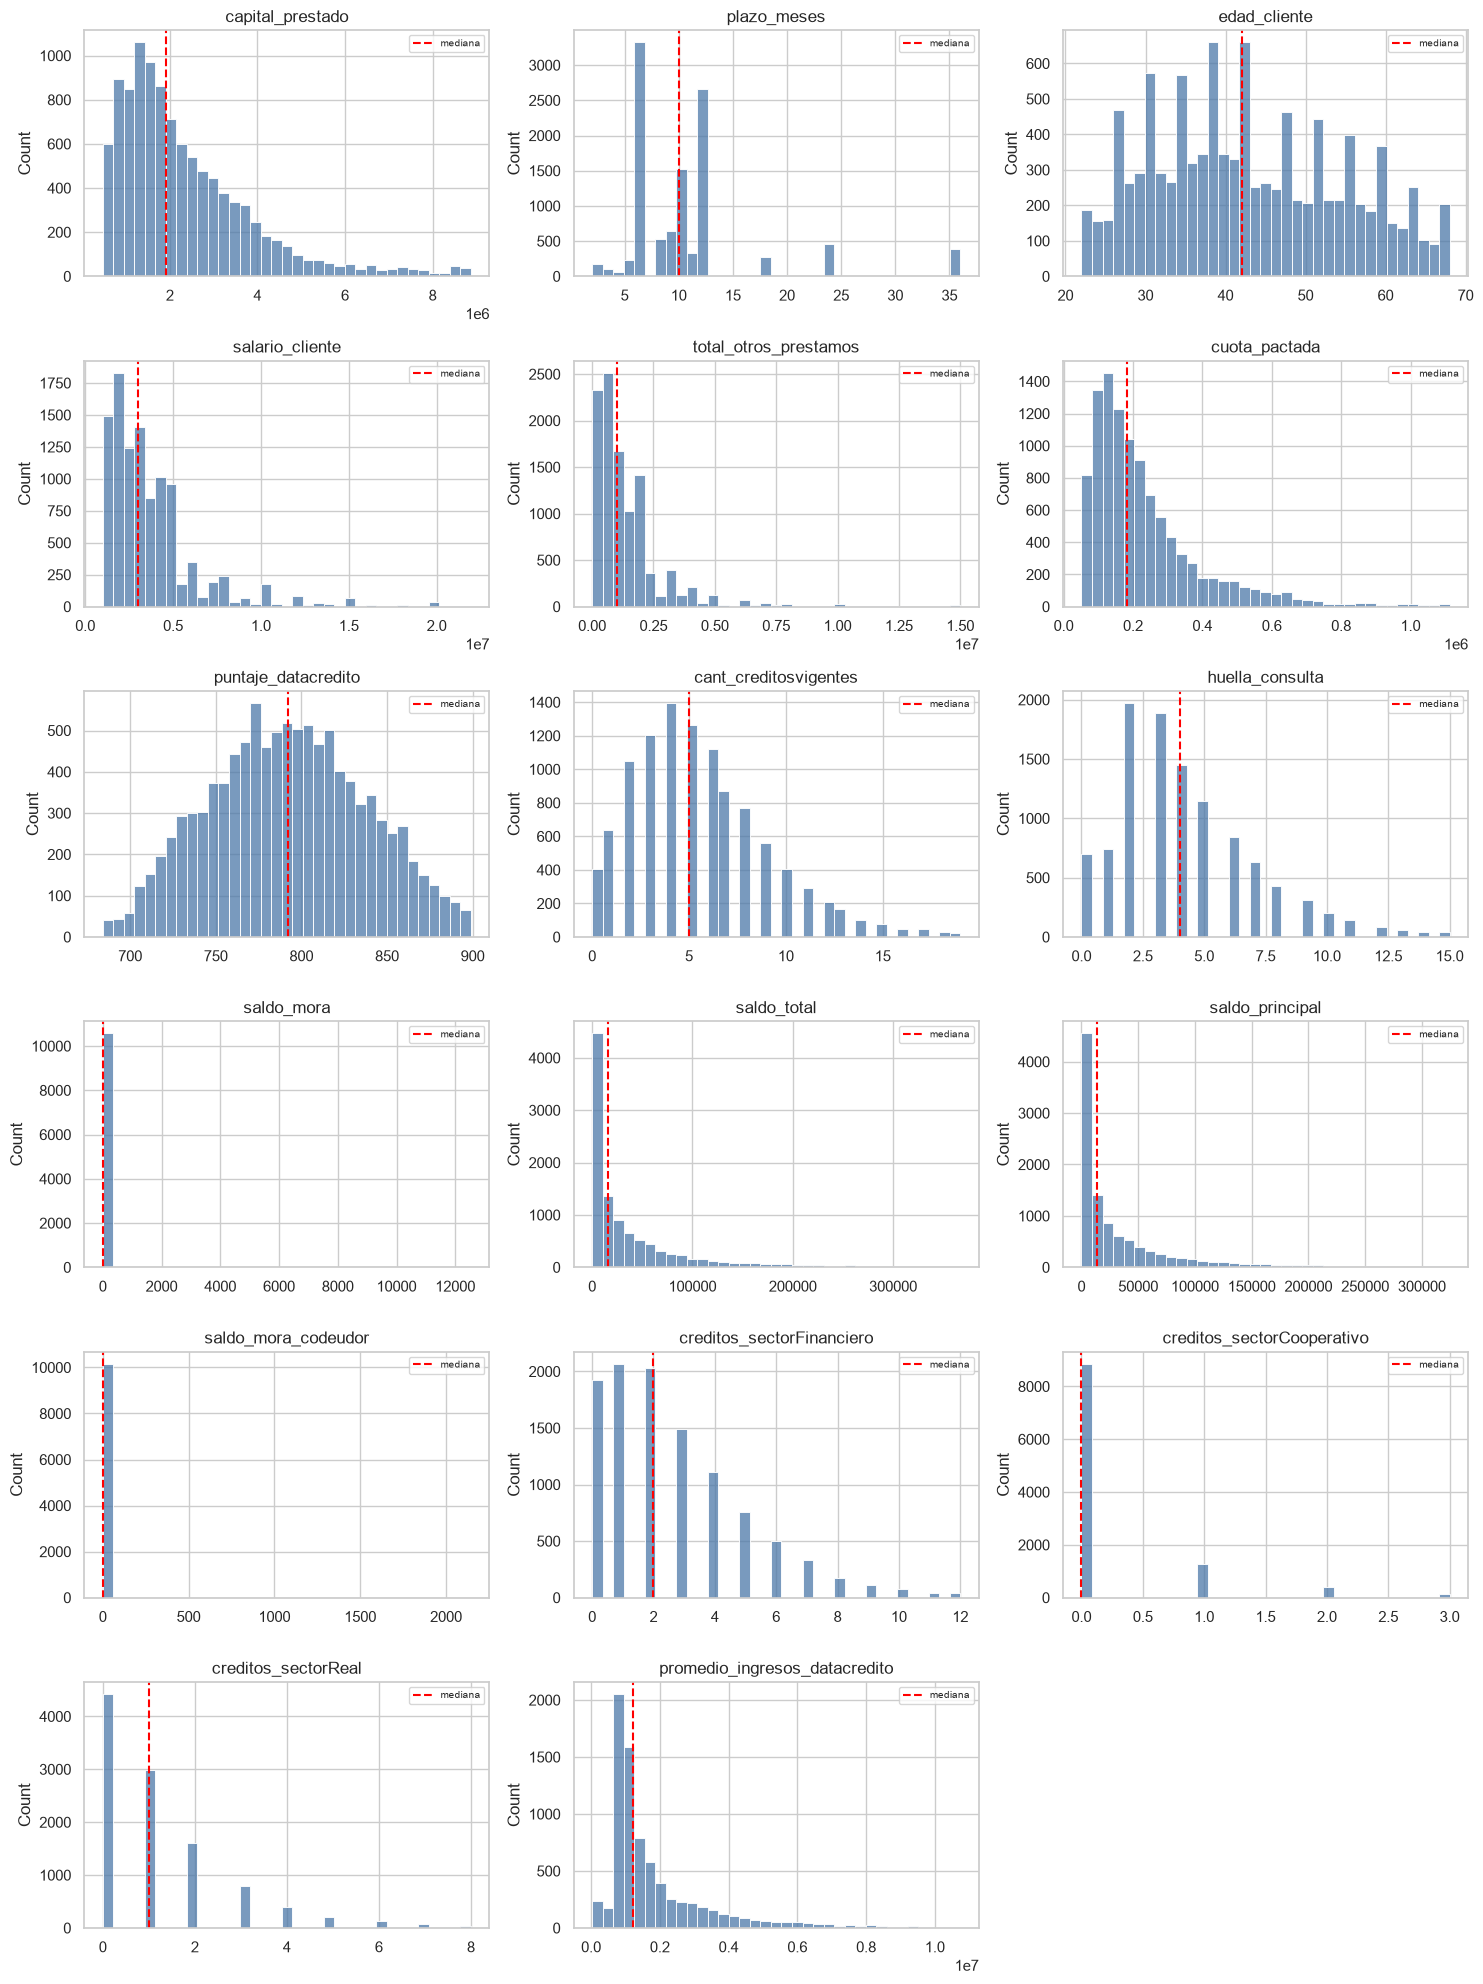

In [20]:
# Histogramas (se recorta al percentil 1-99 para poder ver la forma de la distribución)
fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, col in zip(axes.ravel(), numericas):
    s = df[col].dropna()
    lo, hi = s.quantile([0.01, 0.99])
    sns.histplot(s[(s >= lo) & (s <= hi)] if hi > lo else s, bins=35, kde=False, color="#4c78a8", ax=ax)
    ax.axvline(s.median(), color="red", ls="--", label="mediana")
    ax.set_title(col); ax.set_xlabel(""); ax.legend(fontsize=7)
for ax in axes.ravel()[len(numericas):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

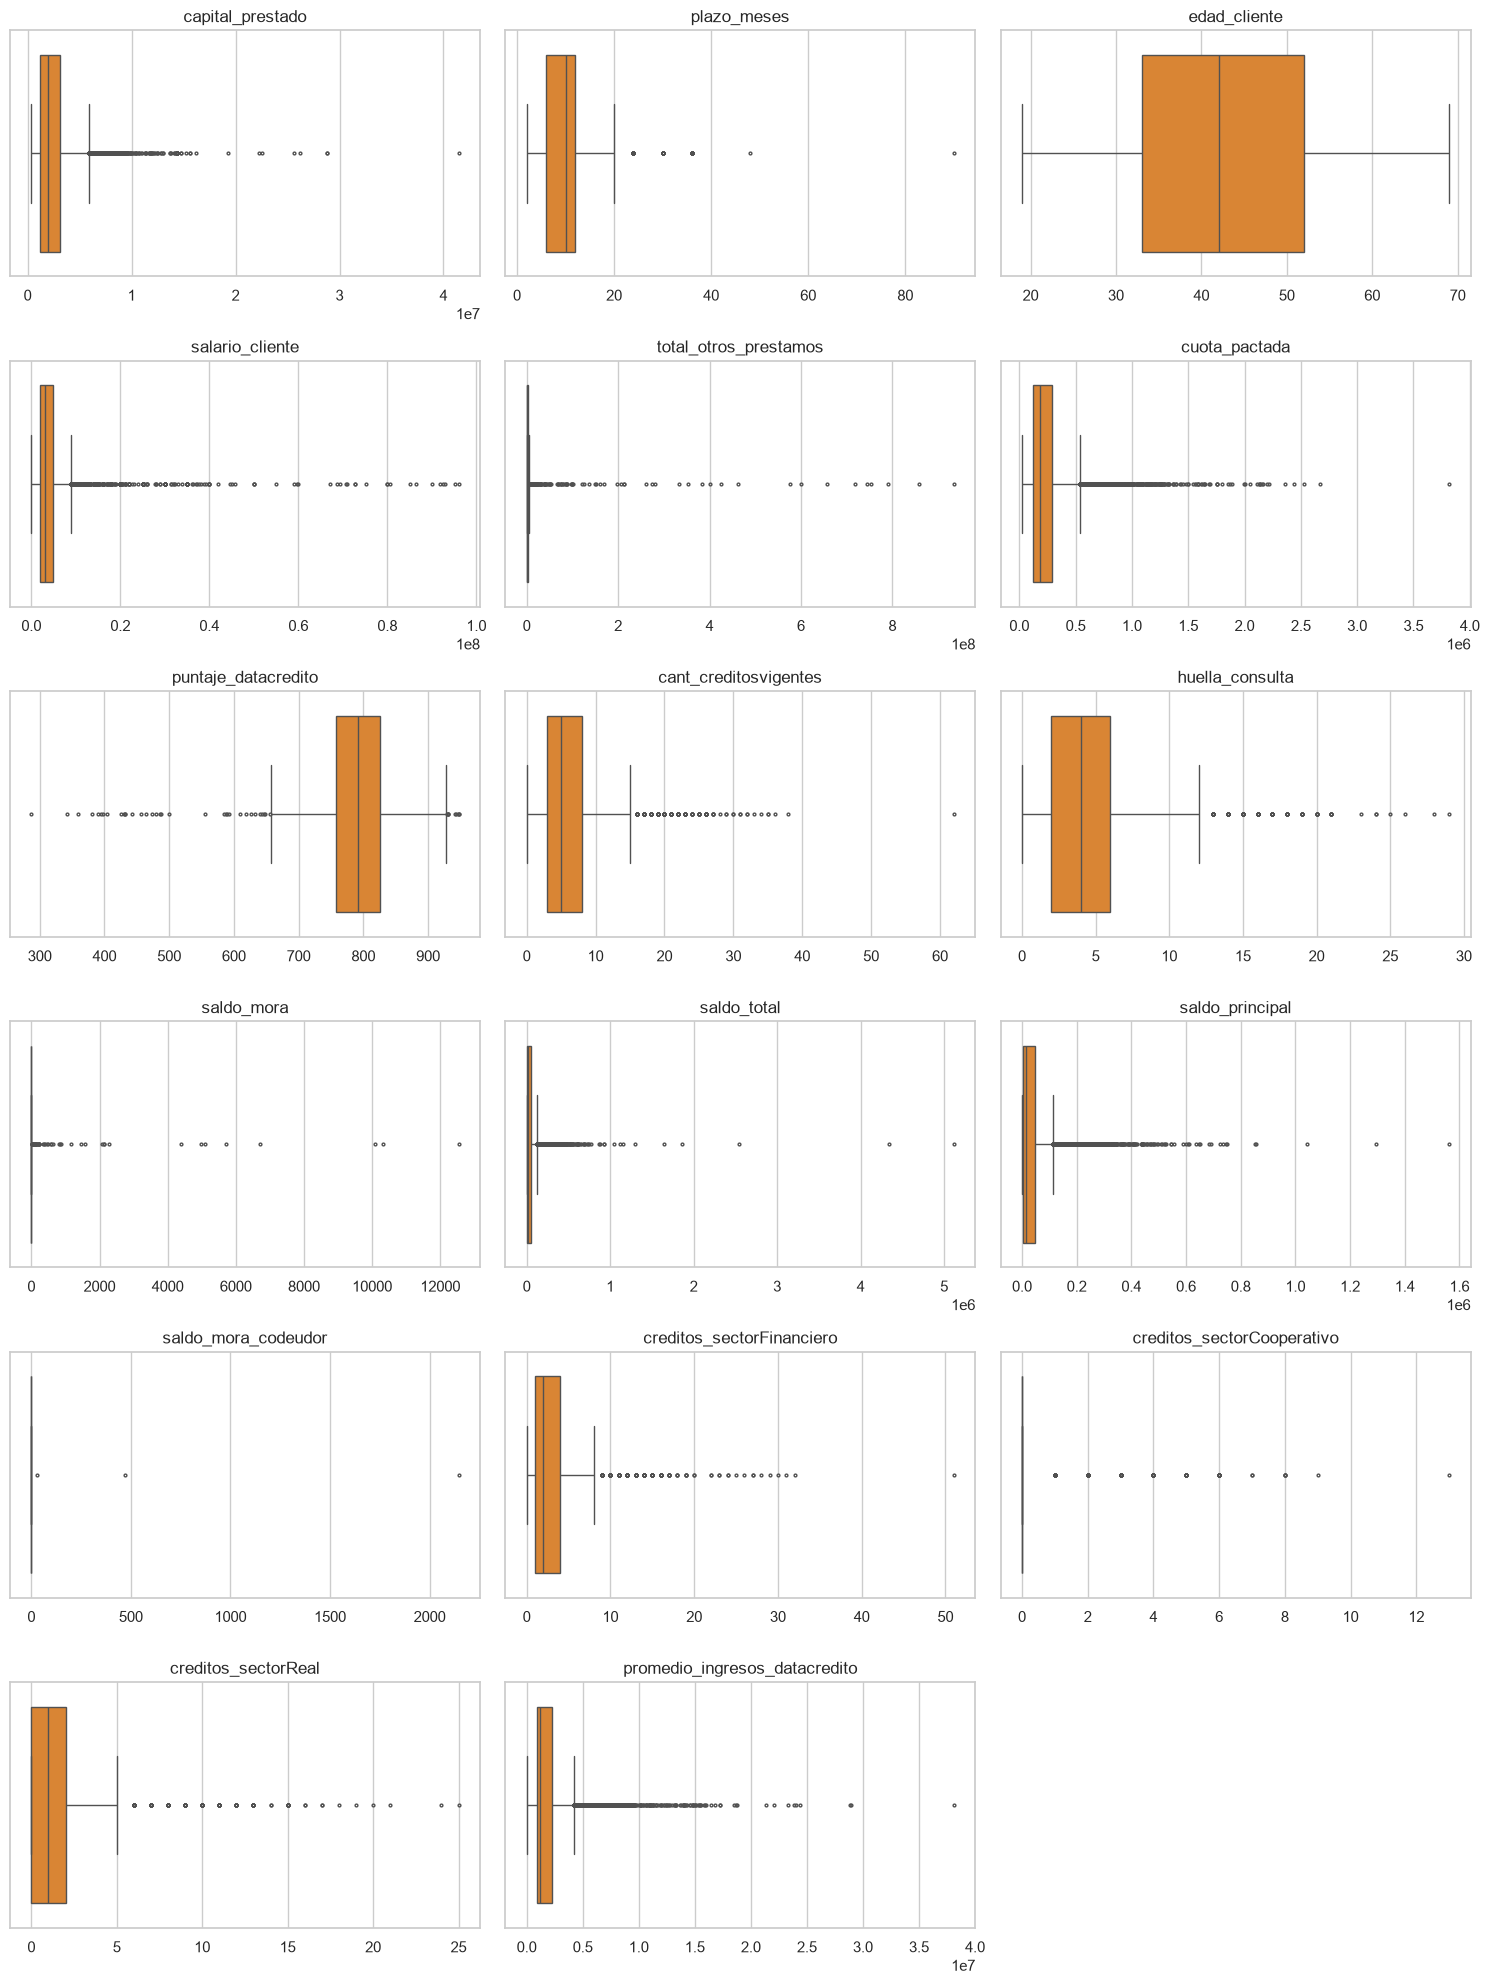

In [21]:
# Boxplots (sin recorte, para ver los valores atípicos reales)
fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, col in zip(axes.ravel(), numericas):
    sns.boxplot(x=df[col], color="#f58518", ax=ax, fliersize=2)
    ax.set_title(col); ax.set_xlabel("")
for ax in axes.ravel()[len(numericas):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [22]:
# Porcentaje de valores atípicos según la regla del IQR (1.5 * IQR)
def pct_atipicos(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return 100 * ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

atipicos = pd.Series({c: pct_atipicos(df[c]) for c in numericas}, name="% atípicos (IQR)").sort_values(ascending=False)
atipicos.round(1).to_frame()

,% atípicos (IQR)
creditos_sectorCooperativo,17.600
promedio_ingresos_datacredito,10.000
saldo_principal,9.300
saldo_total,9.100
plazo_meses,8.100
cuota_pactada,7.100
salario_cliente,6.600
total_otros_prestamos,5.400
capital_prestado,5.100
creditos_sectorFinanciero,3.400


**Interpretación de los atípicos.** Muchas variables de dinero tienen entre 5 % y 10 % de valores atípicos según la regla del IQR (hasta 17,6 % en `creditos_sectorCooperativo`, que es casi siempre 0). Ya eliminamos los **errores evidentes** (salarios imposibles, edad 122);
el resto son clientes legítimos con montos altos que **no se deben borrar** (son parte de la población). Por eso se usa **escalado estándar + modelos robustos (árboles)** y se compara con regresión logística.


### 3.2 Análisis univariable – variables categóricas

In [23]:
categoricas = fe.VARIABLES_CATEGORICAS + fe.VARIABLES_ORDINALES
for col in categoricas:
    print(f"--- {col} ---")
    tabla = pd.DataFrame({"frecuencia": df[col].value_counts(dropna=False),
                          "%": (df[col].value_counts(dropna=False, normalize=True) * 100).round(2)})
    print(tabla.to_string(), "\n")

--- tipo_credito ---
              frecuencia      %
tipo_credito                   
4                   7747 71.980
9                   2876 26.720
10                   116  1.080
6                     21  0.200
7                      2  0.020
68                     1  0.010 

--- tipo_laboral ---
               frecuencia      %
tipo_laboral                    
Empleado             6754 62.750
Independiente        4009 37.250 

--- tendencia_ingresos ---
                    frecuencia      %
tendencia_ingresos                   
Creciente                 5294 49.190
NaN                       2990 27.780
Decreciente               1291 11.990
Estable                   1188 11.040 



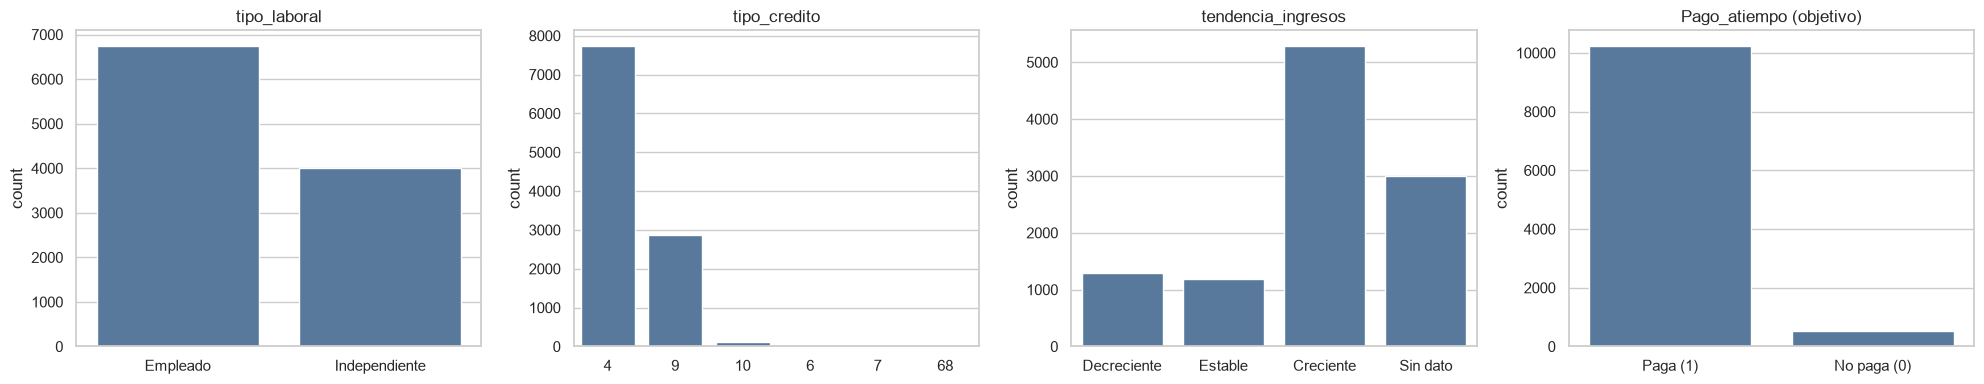

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
orden_tl = df["tipo_laboral"].value_counts().index
sns.countplot(data=df, x="tipo_laboral", order=orden_tl, color="#4c78a8", ax=axes[0])
sns.countplot(data=df, x="tipo_credito", order=df["tipo_credito"].value_counts().index, color="#4c78a8", ax=axes[1])
sns.countplot(data=df.fillna({"tendencia_ingresos": "Sin dato"}), x="tendencia_ingresos",
              order=["Decreciente", "Estable", "Creciente", "Sin dato"], color="#4c78a8", ax=axes[2])
sns.countplot(x=df[TARGET].map({0: "No paga (0)", 1: "Paga (1)"}), color="#4c78a8", ax=axes[3])
for ax, t in zip(axes, ["tipo_laboral", "tipo_credito", "tendencia_ingresos", "Pago_atiempo (objetivo)"]):
    ax.set_title(t); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretación.**

* `tipo_laboral`: ~63 % empleados y ~37 % independientes.
* `tipo_credito`: dominan los códigos **4** (72 %) y **9** (27 %). Los códigos 10, 6, 7 y 68 tienen muy pocos registros (116, 21, 2, 1): se agruparán como "categoría infrecuente" en el `OneHotEncoder` (`min_frequency`).
* `tendencia_ingresos`: es ordinal; "Creciente" es la más común. Hay ~28 % sin dato.
* **Objetivo:** 95,3 % pagan a tiempo y 4,7 % no. Una predicción que diga siempre "paga" tendría 95 % de exactitud y sería inútil → **no se debe usar `accuracy` como métrica principal**; se usarán ROC-AUC, PR-AUC, recall y F1 de la clase 0.


### 3.3 Análisis bivariable (frente a la variable objetivo)

#### Variables numéricas vs `Pago_atiempo`

In [25]:
comparacion = df.groupby(TARGET)[numericas].median().T
comparacion.columns = ["mediana (no paga = 0)", "mediana (paga = 1)"]
comparacion["diferencia %"] = 100 * (comparacion.iloc[:, 0] - comparacion.iloc[:, 1]) / comparacion.iloc[:, 1].replace(0, np.nan)
comparacion

,mediana (no paga = 0),mediana (paga = 1),diferencia %
capital_prestado,"2,268,000.000","1,908,446.400",18.840
plazo_meses,10.000,10.000,0.000
edad_cliente,37.000,42.000,-11.905
salario_cliente,"3,000,000.000","3,000,000.000",0.000
total_otros_prestamos,"900,000.000","1,000,000.000",-10.000
cuota_pactada,"199,002.000","182,576.000",8.997
puntaje_datacredito,769.000,792.000,-2.904
cant_creditosvigentes,5.000,5.000,0.000
huella_consulta,5.000,4.000,25.000
saldo_mora,0.000,0.000,NaN


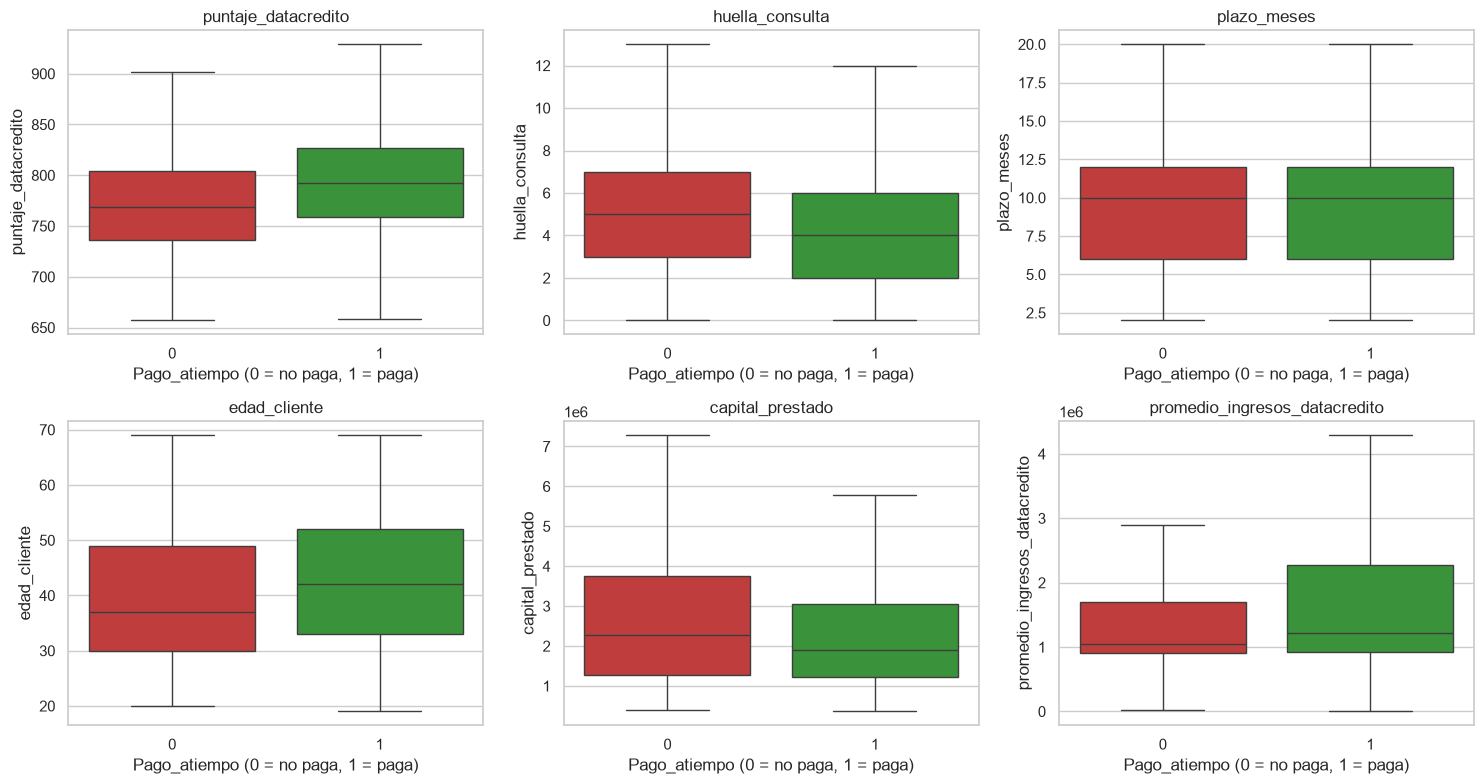

In [26]:
clave = ["puntaje_datacredito", "huella_consulta", "plazo_meses", "edad_cliente", "capital_prestado",
         "promedio_ingresos_datacredito"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), clave):
    sns.boxplot(data=df, x=TARGET, y=col, showfliers=False, palette=PALETA, ax=ax)
    ax.set_title(col); ax.set_xlabel("Pago_atiempo (0 = no paga, 1 = paga)")
plt.tight_layout(); plt.show()

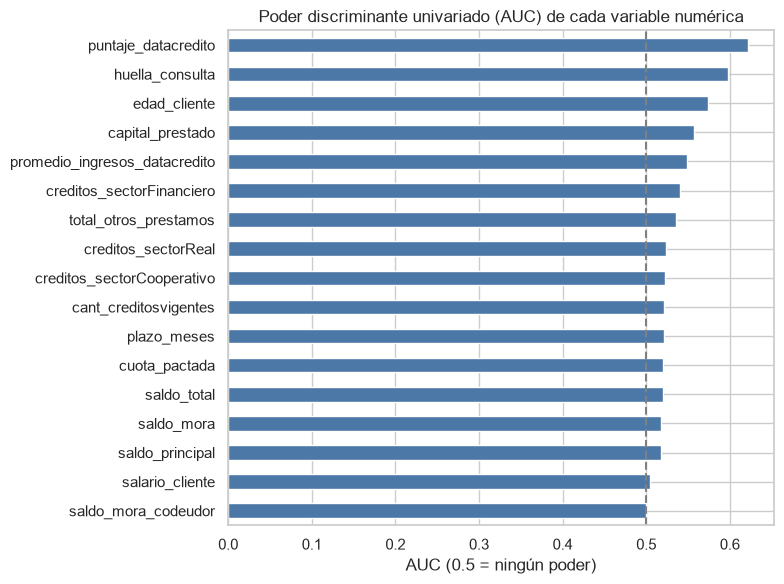

,AUC
puntaje_datacredito,0.622
huella_consulta,0.598
edad_cliente,0.574
capital_prestado,0.557
promedio_ingresos_datacredito,0.548
creditos_sectorFinanciero,0.541


In [27]:
# Poder discriminante univariado: AUC de cada variable por sí sola (imputando con la mediana)
auc = {}
for col in fe.VARIABLES_NUMERICAS_BASE:
    valores = df[col].fillna(df[col].median())
    a = roc_auc_score(df[TARGET], valores)
    auc[col] = max(a, 1 - a)          # 0.5 = sin poder, 1 = perfecto (sin importar el signo)
auc = pd.Series(auc).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
auc.plot(kind="barh", color="#4c78a8", ax=ax)
ax.axvline(0.5, color="gray", ls="--")
ax.set_title("Poder discriminante univariado (AUC) de cada variable numérica")
ax.set_xlabel("AUC (0.5 = ningún poder)")
plt.tight_layout(); plt.show()
auc.sort_values(ascending=False).head(6).round(3).to_frame("AUC")

**Interpretación.**

* Quienes **no pagan** tienen en promedio **menor puntaje en la central** (mediana 769 vs 792), **más consultas recientes** (`huella_consulta`: 5 vs 4), son **más jóvenes** (37 vs 42 años), piden **montos más altos** (capital mediano 2,27 M vs 1,91 M) y con cuotas más altas.
* El poder predictivo de cada variable por separado es **modesto**: la mejor, `puntaje_datacredito`, llega a AUC ≈ 0,62; le siguen `huella_consulta` (0,60), `edad_cliente` (0,57), `capital_prestado` (0,56) y `promedio_ingresos_datacredito` (0,55). Ninguna variable resuelve el problema sola → el modelo deberá **combinar muchas señales débiles** y no se debe esperar un AUC muy alto (con datos reales de riesgo, 0,65–0,75 es habitual).
* El plazo muestra una relación **no lineal**: créditos de más de 12 meses tienen peor tasa de pago (91 %) que los de 10 a 12 meses (97 %). Esto favorece a los modelos de árboles.


In [28]:
# Tasa de pago a tiempo por rangos de las variables más informativas
def tasa_por_rango(col, cortes, etiquetas=None):
    rangos = pd.cut(df[col], cortes, labels=etiquetas)
    return df.groupby(rangos, observed=True)[TARGET].agg(tasa_pago="mean", registros="count").round(3)

print("puntaje_datacredito"); display(tasa_por_rango("puntaje_datacredito", [0, 700, 750, 800, 850, 1000]))
print("huella_consulta");     display(tasa_por_rango("huella_consulta", [-1, 1, 3, 5, 8, 100]))
print("plazo_meses");         display(tasa_por_rango("plazo_meses", [0, 6, 10, 12, 24, 100]))
print("edad_cliente");        display(tasa_por_rango("edad_cliente", [17, 25, 35, 45, 55, 70, 100]))

puntaje_datacredito


,tasa_pago,registros
puntaje_datacredito,,
"(0, 700]",0.849,232
"(700, 750]",0.923,1937
"(750, 800]",0.955,3889
"(800, 850]",0.968,3239
"(850, 1000]",0.971,1307


huella_consulta


,tasa_pago,registros
huella_consulta,,
"(-1, 1]",0.964,1441
"(1, 3]",0.967,3862
"(3, 5]",0.950,2601
"(5, 8]",0.939,1908
"(8, 100]",0.912,951


plazo_meses


,tasa_pago,registros
plazo_meses,,
"(0, 6]",0.952,3905
"(6, 10]",0.953,2718
"(10, 12]",0.968,2982
"(12, 24]",0.932,753
"(24, 100]",0.874,405


edad_cliente


,tasa_pago,registros
edad_cliente,,
"(17, 25]",0.912,568
"(25, 35]",0.938,2723
"(35, 45]",0.960,3176
"(45, 55]",0.966,2216
"(55, 70]",0.960,1930


#### Variables categóricas vs `Pago_atiempo`

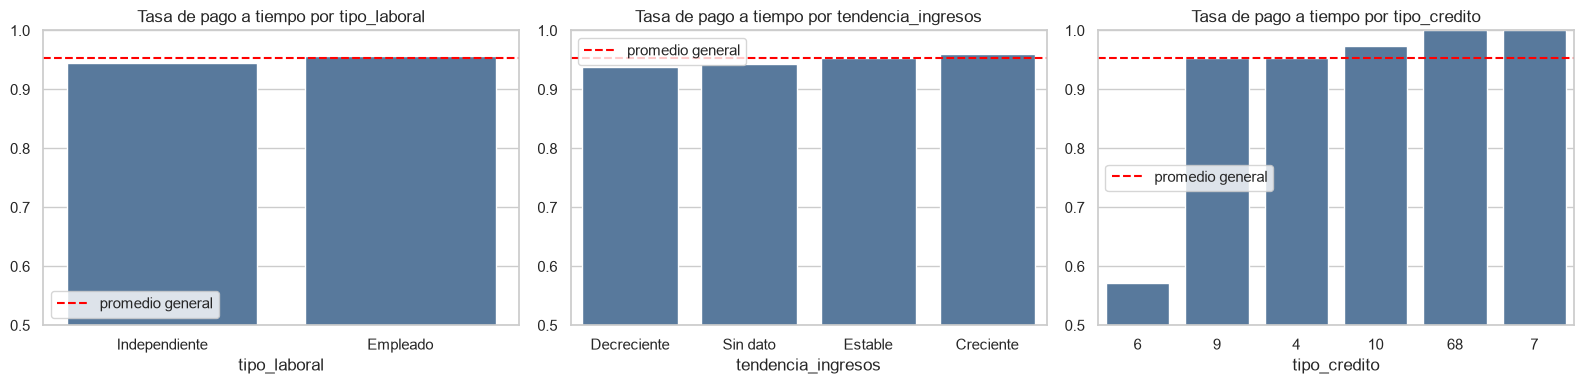

In [29]:
df_cat = df.fillna({"tendencia_ingresos": "Sin dato"})
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tipo_laboral", "tendencia_ingresos", "tipo_credito"]):
    tasa = df_cat.groupby(col)[TARGET].mean().sort_values()
    sns.barplot(x=tasa.index.astype(str), y=tasa.values, color="#4c78a8", ax=ax)
    ax.axhline(df[TARGET].mean(), color="red", ls="--", label="promedio general")
    ax.set_ylim(0.5, 1.0); ax.set_title(f"Tasa de pago a tiempo por {col}"); ax.legend()
plt.tight_layout(); plt.show()

In [30]:
# Pruebas Chi-cuadrado de independencia contra el objetivo
filas = []
for col in ["tipo_laboral", "tendencia_ingresos", "tipo_credito"]:
    tabla = pd.crosstab(df_cat[col], df_cat[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    filas.append({"variable": col, "chi2": chi2, "p-valor": p, "¿relación significativa (p<0.05)?": p < 0.05})
pd.DataFrame(filas)

,variable,chi2,p-valor,¿relación significativa (p<0.05)?
0,tipo_laboral,7.997,0.005,True
1,tendencia_ingresos,19.918,0.000,True
2,tipo_credito,68.857,0.000,True


In [31]:
print("Tasa de pago a tiempo por tipo_credito (con tamaño de muestra):")
df.groupby("tipo_credito")[TARGET].agg(tasa_pago="mean", registros="count").round(3)

Tasa de pago a tiempo por tipo_credito (con tamaño de muestra):


,tasa_pago,registros
tipo_credito,,
10,0.974,116
4,0.953,7747
6,0.571,21
68,1.000,1
7,1.000,2
9,0.953,2876


**Interpretación.**

* **`tipo_laboral`**: los empleados pagan algo mejor (95,7 %) que los independientes (94,5 %).
* **`tendencia_ingresos`**: con ingresos *crecientes* pagan 96,1 %, *estables* 95,4 % y *decrecientes* 93,7 %: hay una relación ordenada, lo que **justifica codificarla como ordinal**.
* **`tipo_credito`**: el código 6 tiene 57 % de pago, pero con solo 21 registros; es ruido por tamaño de muestra, no una conclusión sólida.
* Las pruebas Chi-cuadrado resultan significativas (p < 0,05) para las tres variables; en el caso de `tipo_credito` la significancia viene sobre todo del código 6 (pocos registros), así que debe interpretarse con cautela.


In [32]:
# Tabla pivote: tasa de pago por tipo laboral y tendencia de ingresos
pd.pivot_table(df_cat, values=TARGET, index="tipo_laboral", columns="tendencia_ingresos",
               aggfunc=["mean", "count"]).round(3)

mean                                  count  \
tendencia_ingresos Creciente Decreciente Estable Sin dato Creciente   
tipo_laboral                                                          
Empleado               0.964       0.941   0.955    0.948      3843   
Independiente          0.952       0.927   0.952    0.940      1451   

                                                 
tendencia_ingresos Decreciente Estable Sin dato  
tipo_laboral                                     
Empleado                   937     646     1328  
Independiente              354     542     1662

### 3.4 Análisis multivariable

#### Matriz de correlación

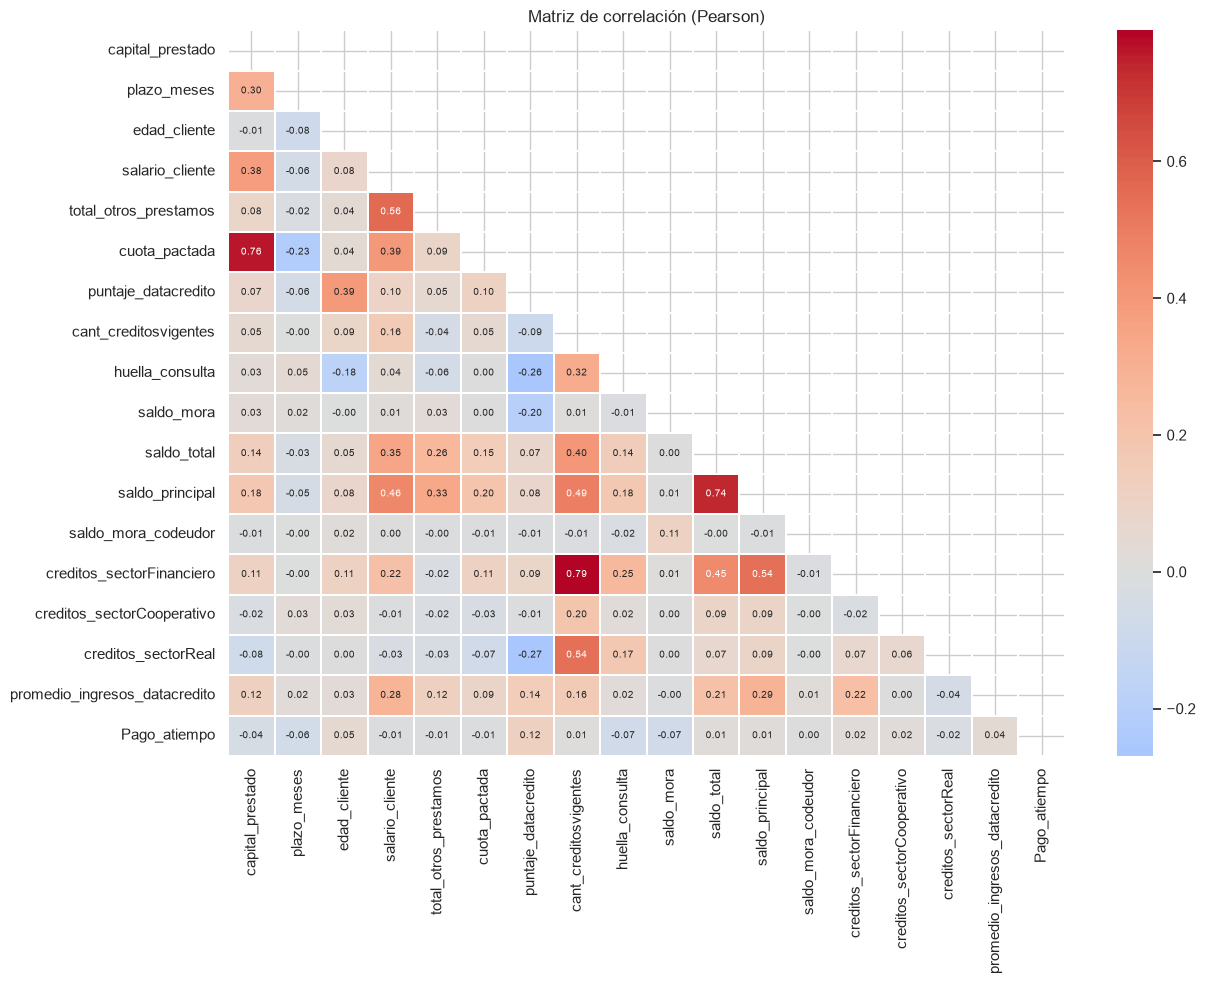

In [33]:
corr = df[numericas + [TARGET]].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mascara, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.3, ax=ax)
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

In [34]:
# Parejas de variables con correlación alta (posible multicolinealidad)
pares = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
pares[pares > 0.6].round(3).to_frame("|correlación|")

,,|correlación|
cant_creditosvigentes,creditos_sectorFinanciero,0.791
capital_prestado,cuota_pactada,0.764
saldo_total,saldo_principal,0.736


In [35]:
# Correlación con el objetivo (sin la variable con fuga 'puntaje')
corr[TARGET].drop(TARGET).sort_values().round(3).to_frame("corr con Pago_atiempo")

,corr con Pago_atiempo
huella_consulta,-0.074
saldo_mora,-0.073
plazo_meses,-0.063
capital_prestado,-0.041
creditos_sectorReal,-0.023
cuota_pactada,-0.012
salario_cliente,-0.011
total_otros_prestamos,-0.010
saldo_mora_codeudor,0.003
cant_creditosvigentes,0.009


**Interpretación.**

* Hay **multicolinealidad** moderada entre variables naturales: `capital_prestado` ↔ `cuota_pactada` (≈0,76), `cant_creditosvigentes` ↔ `creditos_sectorFinanciero` (≈0,79), `saldo_total` ↔ `saldo_principal` (≈0,74). Es esperable: a mayor monto, mayor cuota.
  Para la regresión logística no es grave (se ajusta con regularización L2 por defecto); para árboles no importa.
* Ninguna variable tiene correlación lineal fuerte con el objetivo (la mayor es `puntaje_datacredito` con r ≈ 0,12; el resto |r| < 0,08) → confirma que **la señal es débil y distribuida**.
* Las correlaciones más altas con el objetivo son de signo esperado: más consultas (`huella_consulta`) y más mora → menos pago; mejor puntaje en la central → más pago.


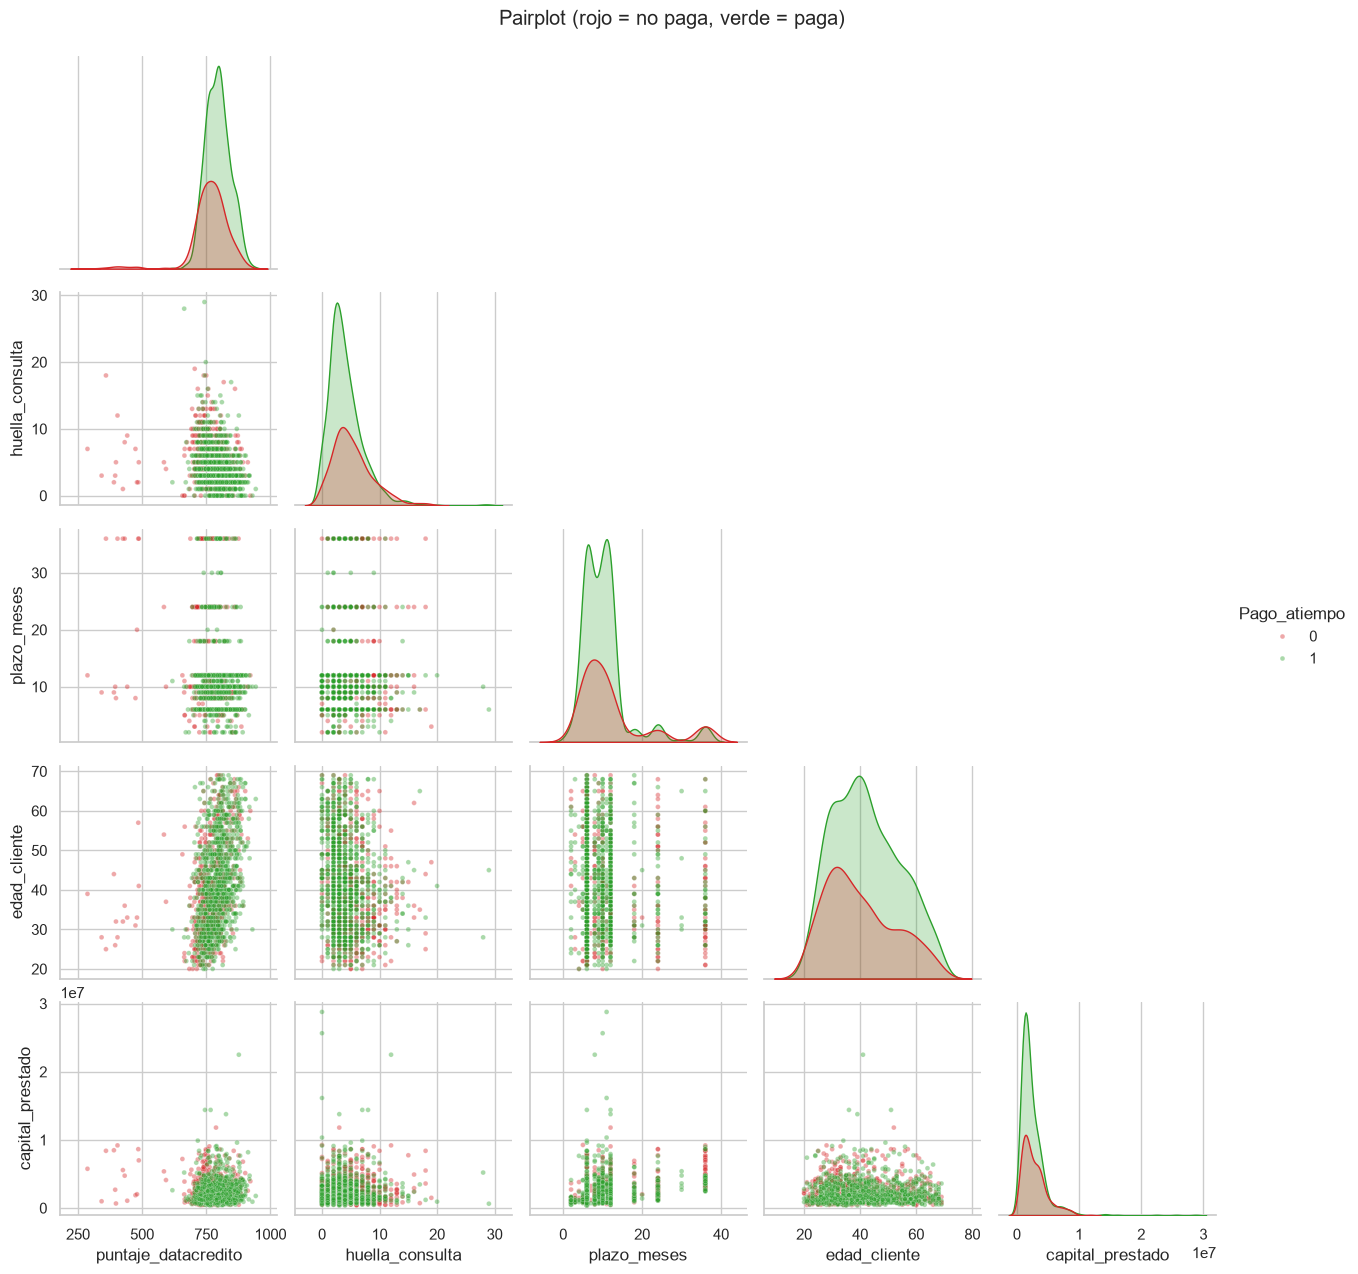

In [36]:
# Pairplot con las variables más informativas (muestra: todos los casos de clase 0 + 1000 de clase 1)
muestra = pd.concat([df[df[TARGET] == 0], df[df[TARGET] == 1].sample(1000, random_state=42)])
vars_pair = ["puntaje_datacredito", "huella_consulta", "plazo_meses", "edad_cliente", "capital_prestado"]
g = sns.pairplot(muestra[vars_pair + [TARGET]], hue=TARGET, palette=PALETA,
                 corner=True, plot_kws={"alpha": 0.4, "s": 12}, diag_kind="kde")
g.figure.suptitle("Pairplot (rojo = no paga, verde = paga)", y=1.02)
plt.show()

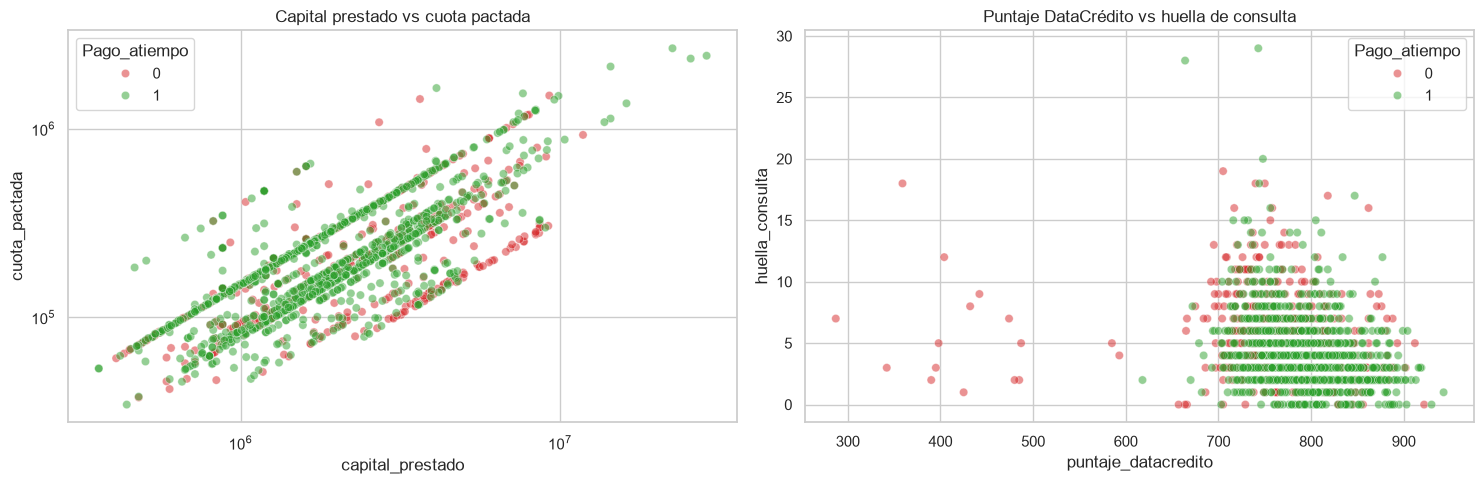

In [37]:
# Dispersión con hue: capital vs cuota, coloreado por el objetivo (escala logarítmica)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=muestra, x="capital_prestado", y="cuota_pactada", hue=TARGET,
                palette=PALETA, alpha=0.5, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Capital prestado vs cuota pactada")
sns.scatterplot(data=muestra, x="puntaje_datacredito", y="huella_consulta", hue=TARGET,
                palette=PALETA, alpha=0.5, ax=axes[1])
axes[1].set(title="Puntaje DataCrédito vs huella de consulta")
plt.tight_layout(); plt.show()

In [38]:
# Tablas cruzadas
print("Distribución de tendencia_ingresos según tipo laboral (% por fila):")
display(pd.crosstab(df["tipo_laboral"], df["tendencia_ingresos"].fillna("Sin dato"), normalize="index").round(3) * 100)
print("Tasa de pago por tipo_laboral y tramo de plazo:")
display(pd.pivot_table(df, values=TARGET, index="tipo_laboral",
                       columns=pd.cut(df["plazo_meses"], [0, 6, 12, 100]), aggfunc="mean", observed=True).round(3))

Distribución de tendencia_ingresos según tipo laboral (% por fila):


tendencia_ingresos,Creciente,Decreciente,Estable,Sin dato
tipo_laboral,,,,
Empleado,56.900,13.900,9.600,19.700
Independiente,36.200,8.800,13.500,41.500


Tasa de pago por tipo_laboral y tramo de plazo:


plazo_meses,"(0, 6]","(6, 12]","(12, 100]"
tipo_laboral,,,
Empleado,0.959,0.966,0.917
Independiente,0.945,0.952,0.892


**Interpretación.**

* En el pairplot los casos de **no pago (rojo)** se mezclan con los de pago: no hay una frontera clara → coherente con un problema difícil y señales débiles.
* Los independientes tienen mucha más proporción de "sin dato" de ingresos (56 % de los nulos son independientes): los empleados tienen más trazabilidad en las centrales.
* El plazo largo (> 12 meses) empeora la tasa de pago tanto en empleados como en independientes.


### 3.5 Atributos derivados (calculados) que pueden ser útiles

Se proponen variables que combinan información existente y tienen sentido financiero. Están implementadas en
`ft_engineering.crear_variables_derivadas`.

In [39]:
derivadas = fe.crear_variables_derivadas(df)[fe.VARIABLES_DERIVADAS + [TARGET]]
derivadas.describe().T

,count,mean,std,min,25%,50%,75%,max
cuota_sobre_salario,"10,665.000",0.095,1.248,0.002,0.039,0.061,0.096,125.802
capital_sobre_salario,"10,665.000",0.928,8.370,0.018,0.375,0.638,1.025,840.000
deuda_sobre_salario,"10,664.000",0.640,23.674,0.000,0.210,0.333,0.475,"2,439.000"
salario_sobre_ingreso_datacredito,"7,805.000",5.495,24.438,0.052,1.081,1.807,3.593,"1,110.970"
total_creditos_sectores,"10,763.000",4.353,3.489,0.000,2.000,4.000,6.000,60.000
mora_total,"10,763.000",7.879,227.282,0.000,0.000,0.000,0.000,"12,534.000"
tiene_mora,"10,763.000",0.005,0.071,0.000,0.000,0.000,0.000,1.000
Pago_atiempo,"10,763.000",0.953,0.213,0.000,1.000,1.000,1.000,1.000


In [40]:
# Relación de cada variable derivada con el objetivo (AUC univariado)
res = {}
for col in fe.VARIABLES_DERIVADAS:
    a = roc_auc_score(derivadas[TARGET], derivadas[col].fillna(derivadas[col].median()))
    res[col] = round(max(a, 1 - a), 3)
pd.Series(res, name="AUC univariado").sort_values(ascending=False).to_frame()

,AUC univariado
salario_sobre_ingreso_datacredito,0.556
deuda_sobre_salario,0.547
capital_sobre_salario,0.540
total_creditos_sectores,0.527
mora_total,0.518
tiene_mora,0.518
cuota_sobre_salario,0.511


Tasa de pago según tenga o no mora (tiene_mora):


,tasa_pago,registros
tiene_mora,,
0,0.954,10708
1,0.636,55


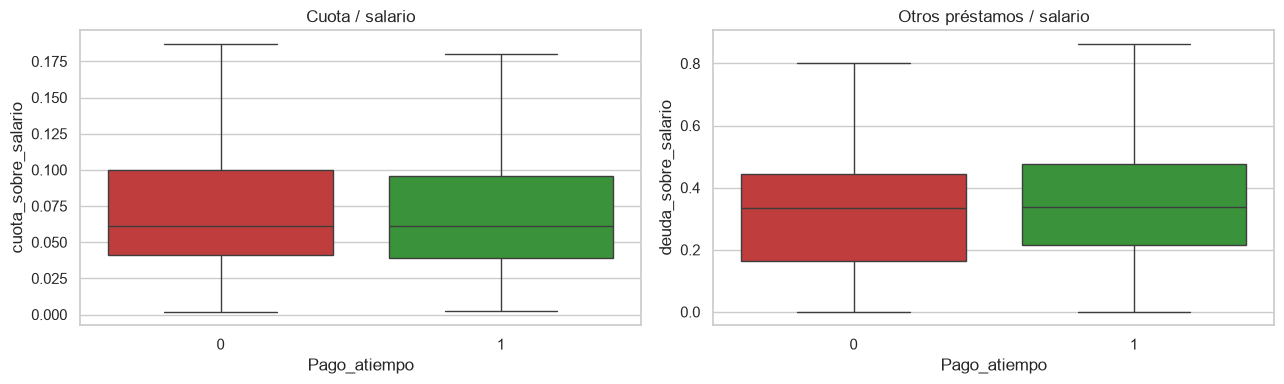

In [41]:
print("Tasa de pago según tenga o no mora (tiene_mora):")
display(derivadas.groupby("tiene_mora")[TARGET].agg(tasa_pago="mean", registros="count").round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=derivadas, x=TARGET, y="cuota_sobre_salario", showfliers=False, ax=axes[0],
            palette=PALETA)
axes[0].set_title("Cuota / salario")
sns.boxplot(data=derivadas, x=TARGET, y="deuda_sobre_salario", showfliers=False, ax=axes[1],
            palette=PALETA)
axes[1].set_title("Otros préstamos / salario")
plt.tight_layout(); plt.show()

**Variables derivadas creadas y por qué:**

| Variable | Fórmula | Razón de negocio |
|---|---|---|
| `cuota_sobre_salario` | cuota / salario | Capacidad de pago: qué parte del ingreso se va en la cuota |
| `capital_sobre_salario` | capital / salario | Tamaño del crédito relativo al ingreso |
| `deuda_sobre_salario` | otros préstamos / salario | Nivel de endeudamiento previo |
| `salario_sobre_ingreso_datacredito` | salario / ingreso reportado | Coherencia entre lo declarado y lo reportado (posible sobredeclaración) |
| `total_creditos_sectores` | suma de créditos de los 3 sectores | Exposición total a crédito |
| `mora_total` | saldo_mora + saldo_mora_codeudor | Mora del cliente y su codeudor |
| `tiene_mora` | mora_total > 0 | Bandera simple de mora |

**Lectura:** `tiene_mora` es muy informativa pero **rara** (solo 55 clientes): los que están en mora pagan a tiempo el 64 % de las veces frente al 95 % de los demás.
Las divisiones se hacen de forma segura (denominador 0 → `NaN`) para no generar infinitos.


### 3.6 Comportamiento en el tiempo

Aunque `fecha_prestamo` no entra al modelo, es clave para **monitorear** el modelo (data drift).

In [42]:
mensual = df.assign(mes=df["fecha_prestamo"].dt.to_period("M")).groupby("mes").agg(
    creditos=(TARGET, "size"), tasa_pago=(TARGET, "mean"),
    capital_mediano=("capital_prestado", "median"), plazo_medio=("plazo_meses", "mean"),
    salario_mediano=("salario_cliente", "median"))
mensual.round(3)

,creditos,tasa_pago,capital_mediano,plazo_medio,salario_mediano
mes,,,,,
2024-11,186,0.930,"1,453,106.400",11.548,"2,500,000.000"
2024-12,1216,0.939,"1,859,740.200",11.415,"2,800,000.000"
2025-01,1917,0.955,"2,015,880.000",10.822,"3,000,000.000"
2025-02,1094,0.941,"1,900,897.800",10.558,"3,000,000.000"
2025-03,1115,0.949,"1,920,000.000",10.447,"3,100,000.000"
2025-04,1102,0.937,"1,819,779.000",10.199,"3,100,000.000"
2025-05,1083,0.957,"1,712,686.800",9.546,"3,400,000.000"
2025-06,665,0.962,"1,845,787.200",9.168,"3,500,000.000"
2025-07,644,0.969,"1,967,940.000",9.370,"3,000,000.000"


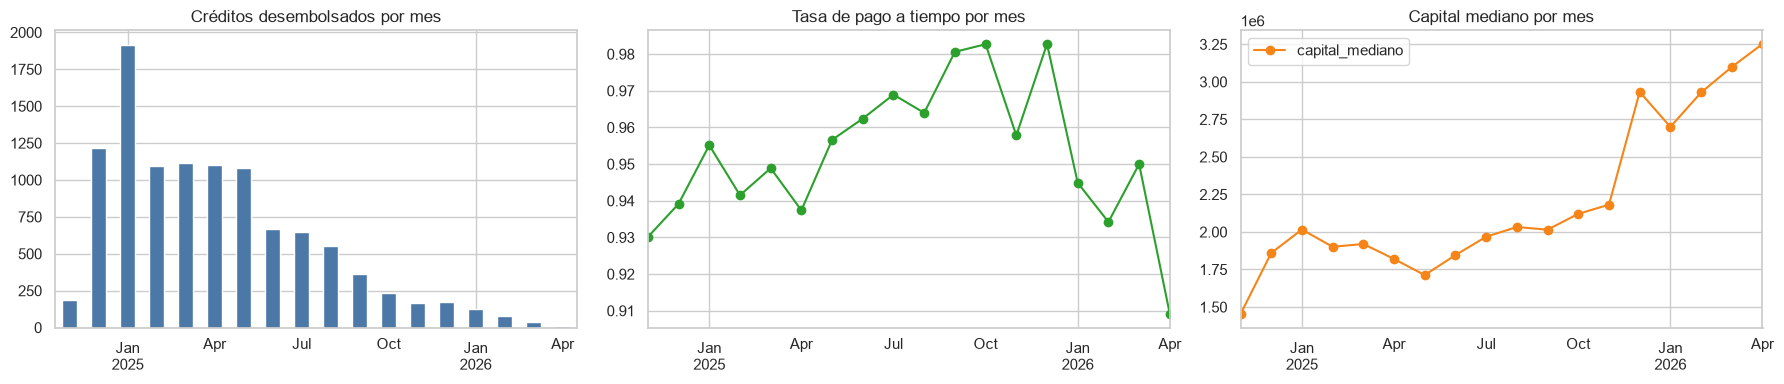

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
mensual["creditos"].plot(kind="bar", ax=axes[0], color="#4c78a8"); axes[0].set_title("Créditos desembolsados por mes")
mensual["tasa_pago"].plot(marker="o", ax=axes[1], color="#2ca02c"); axes[1].set_title("Tasa de pago a tiempo por mes")
mensual[["capital_mediano"]].plot(marker="o", ax=axes[2], color="#f58518"); axes[2].set_title("Capital mediano por mes")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretación.**

* El volumen de desembolsos **cae fuertemente** a partir de mediados de 2025 (de ~1.100 créditos/mes a menos de 200 hacia 2026).
* La composición de la cartera **cambia con el tiempo** (montos, plazos, ingresos), lo que anticipa posible *data drift*: un modelo entrenado con datos antiguos podría degradarse. Por eso existe `model_monitoring.py`.
* Los meses finales tienen pocos registros: sus tasas de pago son poco confiables (ruido por tamaño de muestra).


## 4. Reglas de validación de datos

A partir del análisis se definen reglas que se aplican en el pipeline (`ft_engineering.LIMITES_VALIDOS` y `validar_datos`)
y que se usarán en producción para revisar la calidad de los datos entrantes:

| # | Variable | Regla | Acción si se incumple |
|---|---|---|---|
| 1 | `edad_cliente` | 18 ≤ edad ≤ 100 | Convertir a nulo (122 es centinela) |
| 2 | `salario_cliente` | 1 ≤ salario ≤ 100.000.000 | Convertir a nulo |
| 3 | `total_otros_prestamos` | 0 ≤ valor ≤ 1.000.000.000 | Convertir a nulo |
| 4 | `puntaje_datacredito` | 150 ≤ score ≤ 950 | Convertir a nulo |
| 5 | `capital_prestado`, `cuota_pactada` | > 0 | Convertir a nulo |
| 6 | `plazo_meses` | 1 ≤ plazo ≤ 120 | Convertir a nulo |
| 7 | `tendencia_ingresos` | ∈ {Decreciente, Estable, Creciente} | Convertir a nulo |
| 8 | `saldo_principal` | Si es nulo y `saldo_total = 0` → 0 | Imputar 0 (nulo estructural) |
| 9 | `tipo_credito`, `tipo_laboral` | Categoría conocida | Categorías nuevas se agrupan como "infrecuente" |
| 10 | Columnas obligatorias | Deben existir todas las predictoras | Las que falten se completan con nulo y se imputan |
| 11 | `puntaje` | **No usar** como predictor | Excluir (fuga de datos) |


In [44]:
# Verificación: después de limpiar no debe quedar ningún valor fuera de las reglas
df_limpio = fe.limpiar_datos(df_raw)
reporte = fe.validar_datos(df_limpio)
assert reporte["registros_invalidos"].sum() == 0, "Quedaron valores fuera de rango"
print("✔ Todas las reglas de validación se cumplen después de la limpieza")
reporte

✔ Todas las reglas de validación se cumplen después de la limpieza


,variable,minimo_valido,maximo_valido,registros_invalidos,porcentaje
0,edad_cliente,18.000,100.000,0,0.000
1,salario_cliente,1.000,"100,000,000.000",0,0.000
2,total_otros_prestamos,0.000,"1,000,000,000.000",0,0.000
3,puntaje_datacredito,150.000,950.000,0,0.000
4,capital_prestado,1.000,NaN,0,0.000
5,plazo_meses,1.000,120.000,0,0.000
6,cuota_pactada,1.000,NaN,0,0.000
7,tendencia_ingresos,NaN,NaN,0,0.000


## 5. Transformaciones recomendadas y conclusiones

**Transformaciones que se aplican en `ft_engineering.py` (según el tipo de variable):**

| Tipo | Variables | Transformación |
|---|---|---|
| Numéricas | 17 base + 7 derivadas | `SimpleImputer(mediana, add_indicator=True)` + `StandardScaler` |
| Categóricas nominales | `tipo_credito`, `tipo_laboral` | `SimpleImputer(más frecuente)` + `OneHotEncoder` (categorías raras agrupadas) |
| Categóricas ordinales | `tendencia_ingresos` | `SimpleImputer(más frecuente)` + `OrdinalEncoder` (Decreciente < Estable < Creciente) |

`add_indicator=True` agrega una columna que marca qué datos eran nulos: así el modelo puede aprender que "no tener historial de ingresos" también es información.

**Conclusiones del EDA**

1. La base tiene **10.763 créditos**; el objetivo está **muy desbalanceado** (95,3 % paga / 4,7 % no paga) → métricas apropiadas: ROC-AUC, PR-AUC, recall y F1 de la clase 0; usar `class_weight`.
2. Hay **errores de calidad** (edad 122, salarios imposibles, categorías inválidas en `tendencia_ingresos`, scores fuera de rango) corregidos con reglas explícitas.
3. **`puntaje` tiene fuga de datos** (AUC = 1,0): se excluye. Incluirla habría dado un modelo "perfecto" pero inservible.
4. Las demás variables tienen **señal débil pero real** (puntaje DataCrédito, consultas recientes, edad, plazo, tendencia de ingresos, mora). Es esperable un modelo con AUC moderado (~0,65–0,75).
5. Hay relaciones **no lineales** (plazo) y **multicolinealidad** moderada → se comparan modelos lineales y de árboles.
6. La cartera **cambia en el tiempo** → se justifica el monitoreo de *data drift* con KS, PSI, Jensen-Shannon y Chi-cuadrado.

**Siguiente paso:** `ft_engineering.py` → `model_training_evaluation.py`.
